In [7]:
!nvidia-smi
!nvcc --version

Wed Oct 28 21:29:37 2026       
+-----------------------------------------------------------------------------------------+
| NVIDIA-SMI 580.82.07              Driver Version: 580.82.07      CUDA Version: 13.0     |
+-----------------------------------------+------------------------+----------------------+
| GPU  Name                 Persistence-M | Bus-Id          Disp.A | Volatile Uncorr. ECC |
| Fan  Temp   Perf          Pwr:Usage/Cap |           Memory-Usage | GPU-Util  Compute M. |
|                                         |                        |               MIG M. |
|=========================================+========================+======================|
|   0  Tesla T4                       Off |   00000000:00:04.0 Off |                    0 |
| N/A   37C    P8              9W /   70W |       0MiB /  15360MiB |      0%      Default |
|                                         |                        |                  N/A |
+-----------------------------------------+-----

In [1]:
from pathlib import Path
from PIL import Image
import numpy as np

input_dir = Path("input")
input_dir.mkdir(exist_ok=True)

for i, (w, h) in enumerate([(64, 48), (127, 95), (256, 192)]):
    y, x = np.mgrid[:h, :w]
    img = np.stack([
        (x * 4) % 256,
        (y * 5) % 256,
        ((x + y) * 3) % 256
    ], axis=-1).astype(np.uint8)
    Image.fromarray(img, "RGB").save(input_dir / f"sample_{i}.png")



/tmp/ipykernel_3258/91493773.py:15: DeprecationWarning: 'mode' parameter is deprecated and will be removed in Pillow 13 (2026-10-15)
  Image.fromarray(img, "RGB").save(input_dir / f"sample_{i}.png")


In [5]:
!wget https://raw.githubusercontent.com/nothings/stb/master/stb_image.h

--2026-10-28 23:15:43--  https://raw.githubusercontent.com/nothings/stb/master/stb_image.h
Resolving raw.githubusercontent.com (raw.githubusercontent.com)... 185.199.108.133, 185.199.109.133, 185.199.110.133, ...
Connecting to raw.githubusercontent.com (raw.githubusercontent.com)|185.199.108.133|:443... connected.
HTTP request sent, awaiting response... 200 OK
Length: 283010 (276K) [text/plain]
Saving to: ‘stb_image.h’

stb_image.h         100%[===================>] 276.38K  --.-KB/s    in 0.02s   

2026-10-28 23:15:43 (16.3 MB/s) - ‘stb_image.h’ saved [283010/283010]



In [8]:
!wget https://raw.githubusercontent.com/nothings/stb/master/stb_image_write.h

--2026-10-28 23:16:47--  https://raw.githubusercontent.com/nothings/stb/master/stb_image_write.h
Resolving raw.githubusercontent.com (raw.githubusercontent.com)... 185.199.111.133, 185.199.110.133, 185.199.109.133, ...
Connecting to raw.githubusercontent.com (raw.githubusercontent.com)|185.199.111.133|:443... connected.
HTTP request sent, awaiting response... 200 OK
Length: 71221 (70K) [text/plain]
Saving to: ‘stb_image_write.h’

stb_image_write.h   100%[===================>]  69.55K  --.-KB/s    in 0.008s  

2026-10-28 23:16:47 (9.00 MB/s) - ‘stb_image_write.h’ saved [71221/71221]



In [10]:
!pip install nvcc4jupyter

In [11]:
%reload_ext nvcc4jupyter

Detected platform "Colab". Running its setup...
Source files will be saved in "/tmp/tmpqxl9c6yf".


In [11]:
%%writefile grayscale.cu

#define STB_IMAGE_IMPLEMENTATION
#define STB_IMAGE_WRITE_IMPLEMENTATION

#include <cuda_runtime.h>
#include <cmath>
#include <iostream>
#include <stdexcept>
#include <string>
#include <vector>
#include "stb_image_write.h"
#include "stb_image.h"
#include <filesystem>

namespace fs = std::filesystem;

// Turn CUDA errors into readable messages and stop if an operation failed.
#define CUDA_CHECK(call)                                                   \
    do {                                                                   \
        cudaError_t error = (call);                                        \
        if (error != cudaSuccess) {                                        \
            std::cerr << "CUDA error at " << __FILE__ << ":" << __LINE__  \
                      << ": " << cudaGetErrorString(error) << '\n';        \
            return 1;                                                      \
        }                                                                  \
    } while (0)

struct Image {
    int width;
    int height;
    std::vector<unsigned char> rgb;  // RGBRGBRGB... three bytes per pixel
};

// Read an image into a flat RGB byte array.
Image loadImage(const std::string& path) {
    int width, height, channels;

    unsigned char* imgData =
        stbi_load(path.c_str(), &width, &height, &channels, 3);

    if (imgData == nullptr) {
        throw std::runtime_error(
            "Could not load image: " + path
        );
    }

    Image image{};
    image.width = width;
    image.height = height;

    const size_t valueCount =
        static_cast<size_t>(width) * height * 3;

    if (valueCount >= std::numeric_limits<int>::max()) {
      throw std::runtime_error(
            "Image provided is too big");
    }

    image.rgb.assign(imgData, imgData + valueCount);

    stbi_image_free(imgData);

    return image;
}

// Save flat grayscale bytes as a PNG image.
bool saveImage(const std::string& path, const Image& image) {
    return stbi_write_png(
        path.c_str(),       // Output filename
        image.width,        // Image width
        image.height,       // Image height
        3,                  // Number of channels: RGB
        image.rgb.data(),   // Pointer to pixel data
        image.width * 3     // Bytes per row
    ) != 0;
}

bool saveGrayImage(const std::string& path,
                   const std::vector<unsigned char>& gray,
                   int width,
                   int height) {
    return stbi_write_png(
        path.c_str(),
        width,
        height,
        1,              // One channel: grayscale
        gray.data(),
        width           // One byte per pixel, so stride = width
    ) != 0;
}


// This function runs on the GPU. Each CUDA thread converts one pixel.
__global__ void grayscaleKernel(const unsigned char* input,
                                unsigned char* output,
                                int pixelCount) {
    // Every thread gets a unique one-dimensional index.
    int pixel = blockIdx.x * blockDim.x + threadIdx.x;

    // The final block may contain extra threads, so guard the array access.
    if (pixel >= pixelCount) {
        return;
    }

    int rgbIndex = pixel * 3;
    unsigned char red   = input[rgbIndex + 0];
    unsigned char green = input[rgbIndex + 1];
    unsigned char blue  = input[rgbIndex + 2];

    // Weighted luminance: green contributes most to perceived brightness.
    float gray = 0.299f * red + 0.587f * green + 0.114f * blue;

    // Output has one byte per pixel. Round and clamp to byte range.
    output[pixel] = static_cast<unsigned char>(fminf(255.0f, roundf(gray)));
}

int main(int argc, char* argv[]) {
    if (argc != 3) {
        std::cerr << "Usage: ./grayscale input_folder output_folder\n";
        return 1;
    }

    try {
        fs::path inputDir = argv[1];
        fs::path outputDir = argv[2];

        if (!fs::exists(inputDir) || !fs::is_directory(inputDir)) {
            throw std::runtime_error("Invalid input folder");
        }

        fs::create_directories(outputDir);

        for (const auto& entry : fs::directory_iterator(inputDir)) {
            if (!entry.is_regular_file()) {
                continue;
            }

            const auto extension = entry.path().extension().string();

            if (extension != ".png" && extension != ".jpg" &&
                extension != ".jpeg" && extension != ".bmp") {
                continue;
            }

            std::cout << "Processing: "
                      << entry.path().filename().string() << '\n';

            Image image = loadImage(entry.path().string());
            int pixelCount = image.width * image.height;

            std::vector<unsigned char> gray(pixelCount);

            unsigned char* deviceInput = nullptr;
            unsigned char* deviceOutput = nullptr;

            CUDA_CHECK(cudaMalloc(
                &deviceInput, image.rgb.size()));

            CUDA_CHECK(cudaMalloc(
                &deviceOutput, gray.size()));

            CUDA_CHECK(cudaMemcpy(
                deviceInput, image.rgb.data(),
                image.rgb.size(), cudaMemcpyHostToDevice));

            constexpr int threadsPerBlock = 256;
            int blocks =
                (pixelCount + threadsPerBlock - 1) / threadsPerBlock;

            grayscaleKernel<<<blocks, threadsPerBlock>>>(
                deviceInput, deviceOutput, pixelCount);

            CUDA_CHECK(cudaGetLastError());

            CUDA_CHECK(cudaMemcpy(
                gray.data(), deviceOutput, gray.size(),
                cudaMemcpyDeviceToHost));

            CUDA_CHECK(cudaFree(deviceInput));
            CUDA_CHECK(cudaFree(deviceOutput));

            fs::path outputPath =
                outputDir / (entry.path().stem().string() + "_gray.png");

            if (!saveGrayImage(
                    outputPath.string(), gray,
                    image.width, image.height)) {
                std::cerr << "Failed to save: "
                          << outputPath << '\n';
                continue;
            }

            std::cout << "Saved: " << outputPath << '\n';
        }

        std::cout << "Batch processing complete.\n";
        return 0;

    } catch (const std::exception& error) {
        std::cerr << "Error: " << error.what() << '\n';
        return 1;
    }
}

Overwriting grayscale.cu


In [13]:
!nvcc -std=c++17 grayscale.cu -o grayscale
!./grayscale input/ grayscal/

stb_image.h(4276): warning #550-D: variable "old_limit" was set but never used
     unsigned int cur, limit, old_limit;
                              ^

Remark: The warnings can be suppressed with "-diag-suppress <warning-number>"

stb_image.h(5185): warning #550-D: variable "idata_limit_old" was set but never used
                 stbi__uint32 idata_limit_old = idata_limit;
                              ^

stb_image.h(6972): warning #550-D: variable "out_size" was set but never used
        int out_size = 0;
            ^

stb_image.h(6973): warning #550-D: variable "delays_size" was set but never used
        int delays_size = 0;
            ^

Processing: sample_1.png
Saved: "grayscal/sample_1_gray.png"
Processing: sample_2.png
Saved: "grayscal/sample_2_gray.png"
Processing: sample_0.png
Saved: "grayscal/sample_0_gray.png"
Batch processing complete.


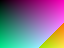

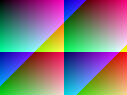

In [20]:
from PIL import Image
display(Image.open("./input/sample_0.png"))
display(Image.open("./input/sample_1.png"))


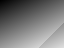

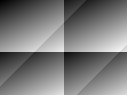

In [21]:
from PIL import Image
display(Image.open("./grayscal/sample_0_gray.png"))
display(Image.open("./grayscal/sample_1_gray.png"))